# 03 · Balanced subset, 20 classes
The same pipeline with Physics split into its sub-archives, 139,600 papers in total.

# Paper Topic Recognition System

## Introduction

This Jupyter Notebook is dedicated to the development of the Paper Topic Recognition System, an automated tool for classifying academic papers into predefined categories based on their textual content. Using a comprehensive dataset from arXiv, which includes over 2 million articles, this project harnesses the power of Natural Language Processing (NLP) and machine learning techniques to efficiently categorize academic papers, enhancing the management and retrieval of scholarly articles.

## Dataset

[arXiv Dataset](https://www.kaggle.com/datasets/Cornell-University/arxiv/data?select=arxiv-metadata-oai-snapshot.json) Version 177.

## Objectives

- **Data Preparation**: Implement preprocessing techniques to clean the dataset, removing noise and standardizing text format for further analysis.
- **Feature Extraction**: Use Term Frequency-Inverse Document Frequency (TF-IDF) for converting textual data into a structured numerical format that facilitates effective machine learning model training.
- **Model Selection and Training**: Explore and evaluate various machine learning algorithms, including Naïve Bayes, K-Nearest Neighbors, Support Vector Machines, and more advanced neural network architectures, to determine the optimal model.
- **Performance Evaluation**: Assess the models using accuracy metrics and cross-validation techniques to ensure reliability and effectiveness in paper categorization.

## Step 1: Load and explore the Data (check preprocessing for implementation file)

In [1]:
%%time

import pandas as pd

data = pd.read_csv('../data/processed_texts_complete.csv')

CPU times: total: 59.9 s
Wall time: 1min 1s


In [2]:
data_display = pd.concat([data.head(1), data.tail(1)])
print(data.shape)
data_display

(2468403, 9)


,title,abstract,categories,clean_abstract,stemmed_clean_abstract,lemmatized_clean_abstract,primary_category,main_primary_category,main_primary_category_physics_expanded
0,Calculation of prompt diphoton production cros...,A fully differential calculation in perturba...,hep-ph,fully differential calculation perturbative qu...,fulli differenti calcul perturb quantum chromo...,fully differential calculation perturbative qu...,hep-ph,Physics,High Energy Physics - Phenomenology
2468402,Ginzburg Landau theory for d-wave pairing and ...,The Ginzburg Landau theory for d_{x^2-y^2}-w...,supr-con cond-mat.supr-con,ginzburg landau theory dx2y2wave superconducto...,ginzburg landau theori dx2y2wav superconductor...,ginzburg landau theory dx2y2wave superconducto...,cond-mat.supr-con,Physics,Condensed Matter


## Step 2: Data Selection

In [3]:
category_group_selected = 'main_primary_category_physics_expanded'     # Select a column group from data

### Create Dataset with same number of samples

In [4]:
# Calculate the percentage of papers in each category
category_counts = data[category_group_selected].value_counts()
category_percentages = data[category_group_selected].value_counts(normalize=True) * 100
print("Percentage of papers in each category:")
print(category_percentages)

print()

# Print the number of entries for all categories
print("Number of entries for each category:")
print(category_counts)

Percentage of papers in each category:
main_primary_category_physics_expanded
Computer Science                              20.423812
Mathematics                                   20.052560
Condensed Matter                              12.573555
Astrophysics                                  12.077647
Physics                                        7.128374
High Energy Physics - Phenomenology            5.309506
Quantum Physics                                4.327940
High Energy Physics - Theory                   4.228199
General Relativity and Quantum Cosmology       2.532690
Statistics                                     1.943200
Electrical Engineering and Systems Science     1.921364
Nuclear Theory                                 1.336856
Mathematical Physics                           1.269282
Quantitative Biology                           1.130245
High Energy Physics - Experiment               0.923877
Nonlinear Sciences                             0.906051
High Energy Physics - Latt

In [5]:
# Find min_category
total_entries = category_counts.sum()
min_category = category_counts.idxmin()
min_count = category_counts.min()
print(f"Total number of entries: {total_entries}")
print(f"Category with the fewest entries: {min_category} ({min_count} entries)")

# Create category_lists
category_lists = {}
unique_categories = data[category_group_selected].unique()
for category in unique_categories:
    key_name = f"{category}_papers"
    category_lists[key_name] = data[data[category_group_selected] == category].sample(n=min_count) # random_state=100700

# Concatanate category_lists
data_same_number_samples = pd.concat(category_lists.values(), ignore_index=True)

Total number of entries: 2468403
Category with the fewest entries: Economics (6980 entries)


In [6]:
data_same_number_samples.shape

(139600, 9)

### Data to train

In [7]:
dataset_to_train = data_same_number_samples # data or data_same_number_samples

In [8]:
processed_text_to_train = 'lemmatized_clean_abstract' #clean_abstract or stemmed_clean_abstract or lemmatized_clean_abstract

In [9]:
print("Before dropping rows:", dataset_to_train.shape)
dataset_to_train = dataset_to_train[~dataset_to_train[processed_text_to_train].isna()]
print(" After dropping rows:", dataset_to_train.shape)

Before dropping rows: (139600, 9)
 After dropping rows: (139600, 9)


## Step 3: Feature Extraction

### Term Frequency-Inverse Document Frequency Algorithm:

$$
\text{TF}(t,d) = \frac{\text{Number of times term } t \text{ appears in document } d}{\text{Total number of terms in document } d}
$$



$$
\text{IDF}(t,D) = \log \left(\frac{\text{Total number of documents in database } D}{\text{Number of documents containing term } t}\right)
$$



$$
\text{TF-IDF}(t,d,D) = \text{TF}(t,d) \times \text{IDF}(t,D)
$$

In [37]:
%%time

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()  # Set max_features=n to limit number of words to n
X = vectorizer.fit_transform(dataset_to_train[processed_text_to_train])

X

CPU times: total: 7.17 s
Wall time: 7.5 s


<139600x290793 sparse matrix of type '<class 'numpy.float64'>'
	with 8559158 stored elements in Compressed Sparse Row format>

In [11]:
row_indices, col_indices = X.nonzero()
first_five = list(zip(row_indices[:5], col_indices[:5]))
last_one = (row_indices[-1], col_indices[-1])

for row, col in first_five:
    print(f'Element at ({row}, {col}) has value {X[row, col]}')

print(f'Last element at ({row_indices[-1]}, {col_indices[-1]}) has value {X[row_indices[-1], col_indices[-1]]}')

Element at (0, 95724) has value 0.10280905806546174
Element at (0, 40023) has value 0.037682440035682364
Element at (0, 270278) has value 0.04040726635977833
Element at (0, 225653) has value 0.06489015388809885
Element at (0, 256401) has value 0.06132152038174889
Last element at (139599, 188496) has value 0.08206791619261133


In [12]:
from sklearn.preprocessing import LabelEncoder

# Encode
label_encoder = LabelEncoder()
Y = label_encoder.fit_transform(dataset_to_train[category_group_selected])
labels = label_encoder.inverse_transform(range(len(label_encoder.classes_)))

### Singular Value Decomposition

In [13]:
import numpy as np
import matplotlib.pyplot as plt

X_32 = X.astype(np.float32) # Consider using if memory is an issue

X_32

<139600x290793 sparse matrix of type '<class 'numpy.float32'>'
	with 8559158 stored elements in Compressed Sparse Row format>

In [ ]:
%%time

from sklearn.decomposition import TruncatedSVD

n_components = 13000 # Adjust as needed

print(f"Trying with {n_components} components...")
svd = TruncatedSVD(n_components=n_components, algorithm='randomized')
svd.fit(X_32) # X or X_32
explained_variance = np.cumsum(svd.explained_variance_ratio_)
print(f"Explained variance ratio: {explained_variance[-1]:.2%}")

# Plotting the cumulative explained variance
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o', linestyle='--')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance by Components')
plt.axhline(y=0.95, color='r', linestyle='-', label='95% variance threshold')
plt.axvline(x=min_components, color='b', linestyle='--', label=f'Min Components: {min_components}')
plt.legend()
plt.grid(True)
plt.show()

Trying with 13000 components...


In [23]:
%%time

# Save the components and singular values to CSV
components_df = pd.DataFrame(svd.components_)
components_df.to_csv("svd_components_13000_same_number_samples.csv", index=False)
components_df

In [25]:
%%time

# Optionally, save the explained variance ratio and singular values
explained_variance_df = pd.DataFrame({
    "Explained Variance Ratio": svd.explained_variance_ratio_,
    "Cumulative Explained Variance": explained_variance,
    "Singular Values": svd.singular_values_
})
explained_variance_df.to_csv("svd_explained_variance_13000_same_number_samples.csv", index=False)
explained_variance_df

CPU times: total: 31.2 ms
Wall time: 37.5 ms


,Explained Variance Ratio,Cumulative Explained Variance,Singular Values
0,0.002631,0.002631,32.912888
1,0.004319,0.006950,15.413301
2,0.003406,0.010356,13.716140
3,0.003084,0.013440,13.149408
4,0.002724,0.016164,12.258734
...,...,...,...
12995,0.000010,0.858160,0.736245
12996,0.000010,0.858170,0.736130
12997,0.000010,0.858180,0.735939
12998,0.000010,0.858190,0.735867


## Step 4: Model Selection

### Encode

In [14]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
Y = label_encoder.fit_transform(dataset_to_train[category_group_selected])
labels = label_encoder.inverse_transform(range(len(label_encoder.classes_)))

### Splitting Data

In [15]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.30, stratify=Y) # random_state=220199

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Training set size: 97720 samples
Testing set size: 41880 samples


In [ ]:
from sklearn.model_selection import train_test_split

X_reduced = svd.transform(X_32)

# Split the data into training and testing sets with SVD
X_train_svd, X_test_svd, Y_train_svd, Y_test_svd = train_test_split(X_reduced, Y, test_size=0.30, stratify=Y) # random_state=220199

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

### 1. Naïve Bayes Classifier

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Training Accuracy: 0.88
Best Cross-Validation Accuracy: 0.75
Test Accuracy: 0.76
Best Alpha: 0.06
                                            precision    recall  f1-score   support

                              Astrophysics       0.91      0.88      0.89      2094
                          Computer Science       0.69      0.63      0.65      2094
                          Condensed Matter       0.76      0.76      0.76      2094
                                 Economics       0.73      0.79      0.76      2094
Electrical Engineering and Systems Science       0.73      0.81      0.77      2094
  General Relativity and Quantum Cosmology       0.74      0.84      0.79      2094
          High Energy Physics - Experiment       0.87      0.82      0.84      2094
             High Energy Physics - Lattice       0.87      0.88      0.87      2094
       High Energy Physics - Phenomenology       0.80      0.67      0.73      2094


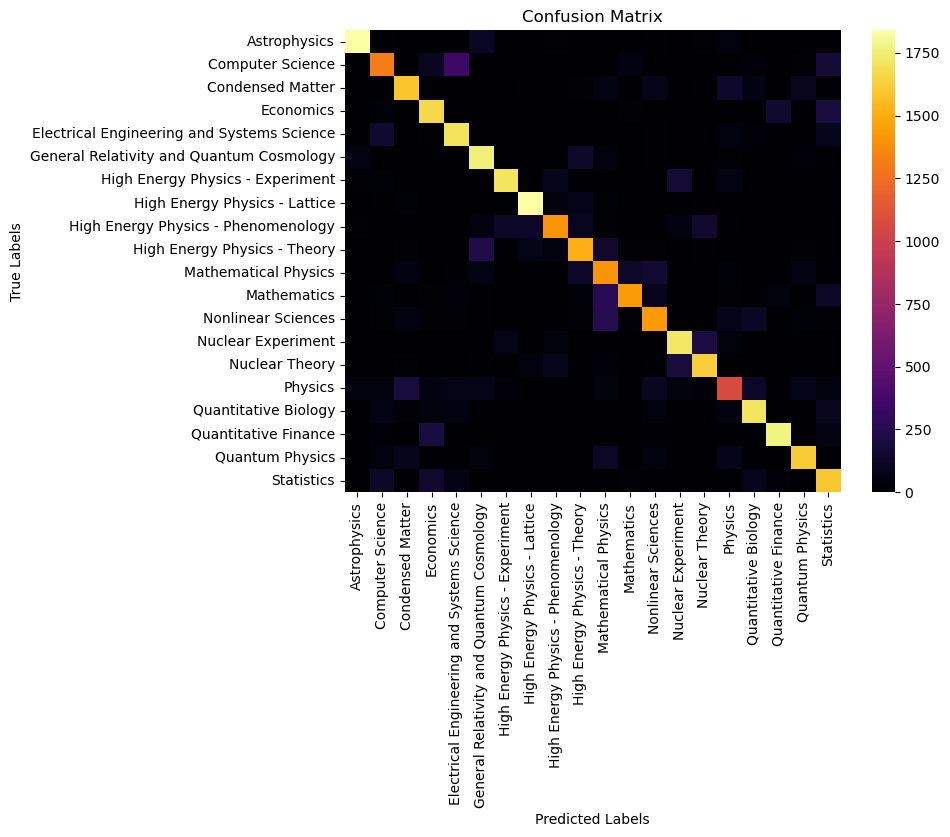

CPU times: total: 1.75 s
Wall time: 9.88 s


In [16]:
%%time

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV
import seaborn as sns

# Params
param_grid = {
    'alpha': [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1]
}

# GridSearchCV
grid_search = GridSearchCV(MultinomialNB(), param_grid, cv=5, scoring='accuracy', verbose=3, n_jobs=2)
grid_search.fit(X_train, Y_train)
best_alpha = grid_search.best_params_['alpha']
best_cross_val_accuracy = grid_search.best_score_

# Train and test
nb_classifier = MultinomialNB(alpha=best_alpha)
nb_classifier.fit(X_train, Y_train)
Y_train_pred = nb_classifier.predict(X_train)
Y_test_pred = nb_classifier.predict(X_test)

# Decode
Y_test_decoded = label_encoder.inverse_transform(Y_test)
Y_test_pred_decoded = label_encoder.inverse_transform(Y_test_pred)

# Evaluate
train_accuracy = accuracy_score(Y_train, Y_train_pred)
test_accuracy = accuracy_score(Y_test, Y_test_pred)
print(f"Training Accuracy: {train_accuracy:.2f}")
print(f"Best Cross-Validation Accuracy: {best_cross_val_accuracy:.2f}")
print(f"Test Accuracy: {test_accuracy:.2f}")
print(f"Best Alpha: {best_alpha:.2f}")
print(classification_report(Y_test_decoded, Y_test_pred_decoded, target_names=labels))

# Generate the confusion matrix
cm = confusion_matrix(Y_test_decoded, Y_test_pred_decoded)

# Plotting the confusion matrix with a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=False, fmt='d', cmap='inferno', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

### K-Nearest Neighbors

Fitting 5 folds for each of 1 candidates, totalling 5 fits
[CV 1/5] END algorithm=brute, metric=euclidean, n_neighbors=111, weights=distance;, score=0.673 total time= 1.1min
[CV 2/5] END algorithm=brute, metric=euclidean, n_neighbors=111, weights=distance;, score=0.676 total time= 1.1min
[CV 3/5] END algorithm=brute, metric=euclidean, n_neighbors=111, weights=distance;, score=0.672 total time= 1.1min
[CV 4/5] END algorithm=brute, metric=euclidean, n_neighbors=111, weights=distance;, score=0.671 total time= 1.4min
[CV 5/5] END algorithm=brute, metric=euclidean, n_neighbors=111, weights=distance;, score=0.676 total time= 1.3min
Training Accuracy: 1.00
Best Cross-Validation Accuracy: 0.67
Test Accuracy: 0.68
Best KNN Parameters: n_neighbors=111, algorithm=brute
                                            precision    recall  f1-score   support

                              Astrophysics       0.82      0.81      0.82      2094
                          Computer Science       0.63      0.5

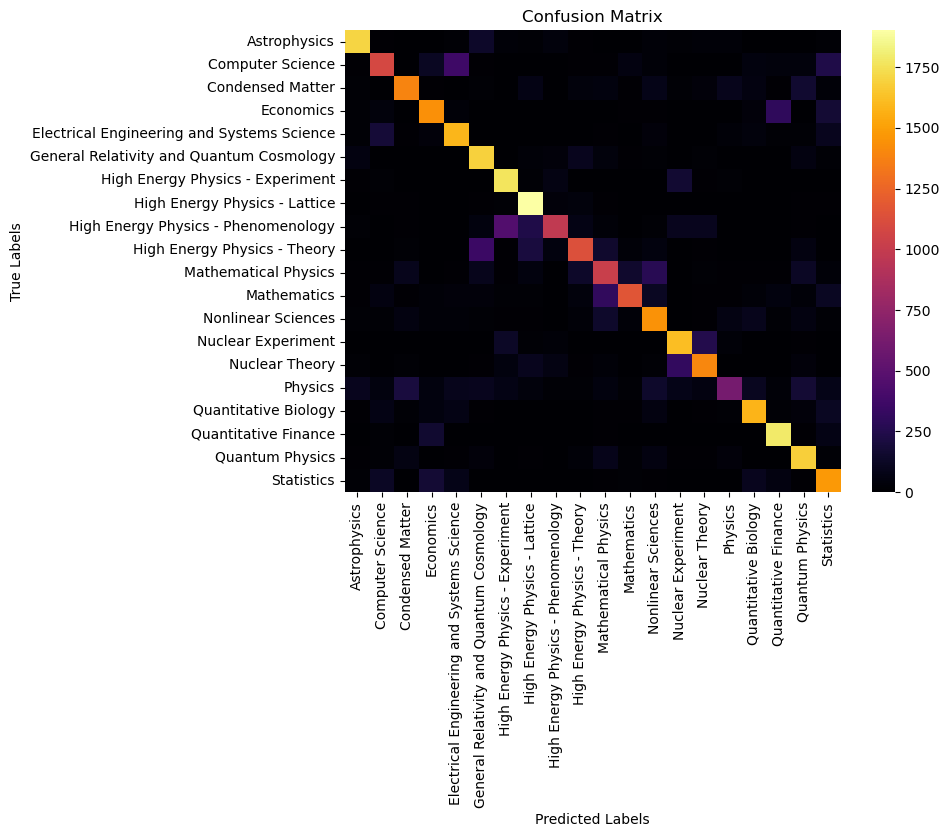

CPU times: total: 20min 25s
Wall time: 15min 26s


In [17]:
%%time

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV

# Params
param_grid = {
    'n_neighbors': [111], #[11, 55, 99, 111, 222, 999]
    'algorithm': ['brute'],
    'weights': ['distance'],
    'metric': ['euclidean']
}

# GridSearchCV
grid_search = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, scoring='accuracy', verbose=3, n_jobs=1)
grid_search.fit(X_train, Y_train)
n_neighbors = grid_search.best_params_['n_neighbors']
weights = grid_search.best_params_['weights']
metric = grid_search.best_params_['metric']
algorithm = grid_search.best_params_['algorithm']
best_cross_val_accuracy = grid_search.best_score_

# Train and test
knn = KNeighborsClassifier(n_neighbors=n_neighbors, weights=weights, metric=metric, algorithm=algorithm, n_jobs=2)
knn.fit(X_train, Y_train)
Y_train_pred = knn.predict(X_train)
Y_test_pred = knn.predict(X_test)

# Decode
Y_test_decoded = label_encoder.inverse_transform(Y_test)
Y_test_pred_decoded = label_encoder.inverse_transform(Y_test_pred)

# Evaluate
train_accuracy = accuracy_score(Y_train, Y_train_pred)
test_accuracy = accuracy_score(Y_test, Y_test_pred)
print(f"Training Accuracy: {train_accuracy:.2f}")
print(f"Best Cross-Validation Accuracy: {best_cross_val_accuracy:.2f}")
print(f"Test Accuracy: {test_accuracy:.2f}")
print(f"Best KNN Parameters: n_neighbors={n_neighbors}, algorithm={algorithm}")
print(classification_report(Y_test_decoded, Y_test_pred_decoded, target_names=labels))

# Generate the confusion matrix
cm = confusion_matrix(Y_test_decoded, Y_test_pred_decoded)

# Plotting the confusion matrix with a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=False, fmt='d', cmap='inferno', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

### Support Vector Machines

Fitting 5 folds for each of 3 candidates, totalling 15 fits
[CV 1/5] END .C=0.1, dual=auto, multi_class=ovr;, score=0.761 total time=   4.9s
[CV 2/5] END .C=0.1, dual=auto, multi_class=ovr;, score=0.759 total time=   5.0s
[CV 3/5] END .C=0.1, dual=auto, multi_class=ovr;, score=0.759 total time=   4.9s
[CV 4/5] END .C=0.1, dual=auto, multi_class=ovr;, score=0.755 total time=   4.9s
[CV 5/5] END .C=0.1, dual=auto, multi_class=ovr;, score=0.762 total time=   4.9s
[CV 1/5] END .C=0.2, dual=auto, multi_class=ovr;, score=0.766 total time=   5.2s
[CV 2/5] END .C=0.2, dual=auto, multi_class=ovr;, score=0.763 total time=   5.1s
[CV 3/5] END .C=0.2, dual=auto, multi_class=ovr;, score=0.763 total time=   5.0s
[CV 4/5] END .C=0.2, dual=auto, multi_class=ovr;, score=0.759 total time=   5.4s
[CV 5/5] END .C=0.2, dual=auto, multi_class=ovr;, score=0.768 total time=   4.9s
[CV 1/5] END .C=0.3, dual=auto, multi_class=ovr;, score=0.766 total time=   5.3s
[CV 2/5] END .C=0.3, dual=auto, multi_class=ovr;,

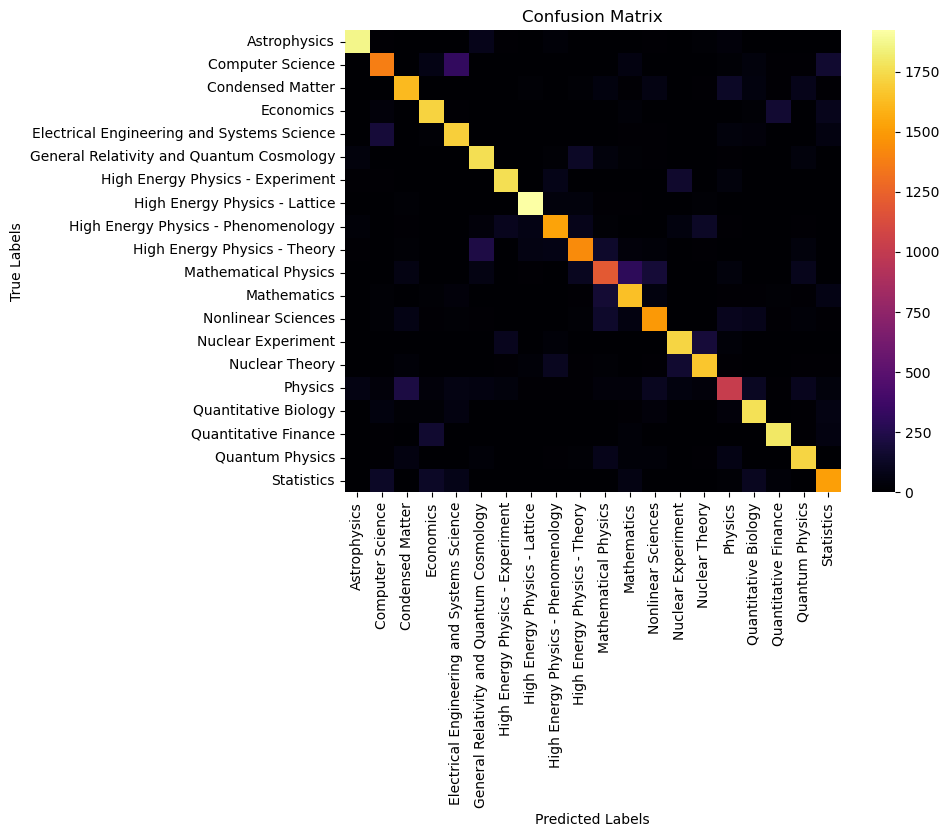

CPU times: total: 1min 32s
Wall time: 1min 34s


In [18]:
%%time

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV

# Params
param_grid = {
    'C': [0.1, 0.2, 0.3],
    'multi_class': ['ovr'],
    'dual': ['auto']
}

# GridSearchCV
grid_search = GridSearchCV(LinearSVC(), param_grid, cv=5, scoring='accuracy', verbose=3, n_jobs=1)
grid_search.fit(X_train, Y_train)
C = grid_search.best_params_['C']
multi_class = grid_search.best_params_['multi_class']
dual = grid_search.best_params_['dual']
best_cross_val_accuracy = grid_search.best_score_

# Train and test
svm_classifier = LinearSVC(C=C, multi_class=multi_class, dual=dual)
svm_classifier.fit(X_train, Y_train)
Y_train_pred = svm_classifier.predict(X_train)
Y_test_pred = svm_classifier.predict(X_test)

# Decode
Y_test_decoded = label_encoder.inverse_transform(Y_test)
Y_test_pred_decoded = label_encoder.inverse_transform(Y_test_pred)

# Evaluate
train_accuracy = accuracy_score(Y_train, Y_train_pred)
test_accuracy = accuracy_score(Y_test, Y_test_pred)
print(f"Training Accuracy: {train_accuracy:.2f}")
print(f"Best Cross-Validation Accuracy: {best_cross_val_accuracy:.2f}")
print(f"Test Accuracy: {test_accuracy:.2f}")
print(f"Best SVM Parameters: C={C}")
print(classification_report(Y_test_decoded, Y_test_pred_decoded, target_names=labels))

# Generate the confusion matrix
cm = confusion_matrix(Y_test_decoded, Y_test_pred_decoded)

# Plotting the confusion matrix with a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=False, fmt='d', cmap='inferno', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

### Testing single paper

In [71]:
random_paper = data[data['main_primary_category'] == 'Physics'].sample(n=1)
random_paper

,title,abstract,categories,clean_abstract,stemmed_clean_abstract,lemmatized_clean_abstract,primary_category,main_primary_category,main_primary_category_physics_expanded
683125,Ab initio molecular dynamics with nuclear quan...,Path integral molecular dynamics simulations...,physics.chem-ph cond-mat.stat-mech,path integral molecular dynamics simulations c...,path integr molecular dynam simul combin ab in...,path integral molecular dynamic simulation com...,physics.chem-ph,Physics,Physics


In [72]:
print(random_paper['lemmatized_clean_abstract'].iloc[0])

path integral molecular dynamic simulation combine ab initio evaluation interaction use electronic structure theory incorporate quantum mechanical nature electron nucleus essential accurately describe system contain light nucleus however path integral simulation traditionally require computational cost around two order magnitude great treat nucleus classically make prohibitively costly application show cost path integral simulation dramatically reduce extend ring polymer contraction approach ab initio molecular dynamic simulation use density functional tight bind reference system show ab initio ring polymer contraction airpc scheme give rapid systematic convergence full path integral density functional theory result demonstrate efficiency approach ab initio simulation liquid water reactive protonate deprotonate water dimer system find vast majority nuclear quantum effect accurately capture use contraction ring polymer centroid require number density functional theory calculation classi

In [73]:
features_random_paper = vectorizer.transform(random_paper['lemmatized_clean_abstract'])
features_random_paper

<1x290793 sparse matrix of type '<class 'numpy.float64'>'
	with 98 stored elements in Compressed Sparse Row format>

In [74]:
print(random_paper['main_primary_category_physics_expanded'].iloc[0])

Physics


In [75]:
prediction = nb_classifier.predict(features_random_paper)
decoded_prediction = label_encoder.inverse_transform(prediction)
print(decoded_prediction[0])

Physics


In [76]:
prediction = knn.predict(features_random_paper)
decoded_prediction = label_encoder.inverse_transform(prediction)
print(decoded_prediction[0])

Nuclear Theory


In [77]:
prediction = svm_classifier.predict(features_random_paper)
decoded_prediction = label_encoder.inverse_transform(prediction)
print(decoded_prediction[0])

Physics
